
# Handwritten Digit Recognition Using Neural Networks (MNIST)

## Project Overview

This project focuses on developing a Neural Network model capable of recognizing handwritten digits from 0 to 9.

The project uses the MNIST (Modified National Institute of Standards and Technology) dataset, which contains 70,000 grayscale images of handwritten digits.

## Project Objectives

1. Load and understand the MNIST dataset.
2. Perform data exploration and visualization.
3. Preprocess handwritten digit images.
4. Develop an Artificial Neural Network (ANN).
5. Train the model using the training dataset.
6. Evaluate the model using testing data.
7. Predict handwritten digits using the trained model.
8. Develop an interactive digit recognition interface.

## Dataset Information

- Dataset: MNIST
- Total Images: 70,000
- Training Images: 60,000
- Testing Images: 10,000
- Image Dimensions: 28 × 28 pixels
- Image Type: Grayscale
- Number of Classes: 10
- Classes: Digits 0 to 9

## Technologies Used

- Python
- Google Colab
- TensorFlow
- Keras
- NumPy
- Matplotlib
- Scikit-learn
- Gradio

## Expected Outcome

A trained Neural Network model that can identify handwritten digits from 0 to 9 and display its predictions through an interactive interface.

---

**Developed by: SANKET KISHOR SUTAR**


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import random

np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

sns.set_theme(style="whitegrid")

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [ ]:
import sklearn

print("LIBRARY VERSION DETAILS")
print("------------------------------")

print("Python environment: Google Colab")
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("TensorFlow Version:", tf.__version__)
print("Scikit-learn Version:", sklearn.__version__)

print("------------------------------")
print("Environment verification completed!")

LIBRARY VERSION DETAILS
------------------------------
Python environment: Google Colab
NumPy Version: 2.4.6
Pandas Version: 2.2.3
TensorFlow Version: 2.21.0
Scikit-learn Version: 1.6.1
------------------------------
Environment verification completed!


In [ ]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("MNIST DATASET LOADED SUCCESSFULLY!")
print("-----------------------------------")

print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing images shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)

print("-----------------------------------")
print("Training dataset size:", len(x_train))
print("Testing dataset size:", len(x_test))
print("Total number of images:", len(x_train) + len(x_test))

print("-----------------------------------")
print("Image dimensions:", x_train.shape[1], "x", x_train.shape[2])
print("Pixel value range:", x_train.min(), "to", x_train.max())
print("Available digit labels:", np.unique(y_train))

assert x_train.shape == (60000, 28, 28)
assert y_train.shape == (60000,)
assert x_test.shape == (10000, 28, 28)
assert y_test.shape == (10000,)

print("-----------------------------------")
print("Dataset verification completed successfully!")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MNIST DATASET LOADED SUCCESSFULLY!
-----------------------------------
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)
-----------------------------------
Training dataset size: 60000
Testing dataset size: 10000
Total number of images: 70000
-----------------------------------
Image dimensions: 28 x 28
Pixel value range: 0 to 255
Available digit labels: [0 1 2 3 4 5 6 7 8 9]
-----------------------------------
Dataset verification completed successfully!


In [ ]:
print("MNIST DATASET STRUCTURE")
print("-----------------------------------")

print("TRAINING DATA")
print("Number of images:", len(x_train))
print("Image dimensions:", x_train.shape[1:])
print("Image data type:", x_train.dtype)
print("Label data type:", y_train.dtype)

print("-----------------------------------")

print("TESTING DATA")
print("Number of images:", len(x_test))
print("Image dimensions:", x_test.shape[1:])
print("Image data type:", x_test.dtype)
print("Label data type:", y_test.dtype)

print("-----------------------------------")

print("PIXEL INFORMATION")
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Pixels per image:", x_train.shape[1] * x_train.shape[2])

print("-----------------------------------")

print("AVAILABLE DIGIT CLASSES:", np.unique(y_train))
print("NUMBER OF CLASSES:", len(np.unique(y_train)))

print("-----------------------------------")
print("Dataset structure analysis completed!")

MNIST DATASET STRUCTURE
-----------------------------------
TRAINING DATA
Number of images: 60000
Image dimensions: (28, 28)
Image data type: uint8
Label data type: uint8
-----------------------------------
TESTING DATA
Number of images: 10000
Image dimensions: (28, 28)
Image data type: uint8
Label data type: uint8
-----------------------------------
PIXEL INFORMATION
Minimum pixel value: 0
Maximum pixel value: 255
Pixels per image: 784
-----------------------------------
AVAILABLE DIGIT CLASSES: [0 1 2 3 4 5 6 7 8 9]
NUMBER OF CLASSES: 10
-----------------------------------
Dataset structure analysis completed!


In [ ]:
train_counts = np.bincount(y_train, minlength=10)
test_counts = np.bincount(y_test, minlength=10)

train_percentages = (train_counts / len(y_train)) * 100
test_percentages = (test_counts / len(y_test)) * 100

digit_distribution = pd.DataFrame({
    "Digit": np.arange(10),
    "Training Images": train_counts,
    "Training Percentage (%)": train_percentages.round(2),
    "Testing Images": test_counts,
    "Testing Percentage (%)": test_percentages.round(2)
})

print("MNIST DIGIT CLASS DISTRIBUTION")
print("-----------------------------------")

display(digit_distribution)

print("-----------------------------------")
print("Total training images:", train_counts.sum())
print("Total testing images:", test_counts.sum())
print("Total images:", train_counts.sum() + test_counts.sum())

print("-----------------------------------")
print("Digit distribution analysis completed!")

MNIST DIGIT CLASS DISTRIBUTION
-----------------------------------


,Digit,Training Images,Training Percentage (%),Testing Images,Testing Percentage (%)
0,0,5923,9.87,980,9.80
1,1,6742,11.24,1135,11.35
2,2,5958,9.93,1032,10.32
3,3,6131,10.22,1010,10.10
4,4,5842,9.74,982,9.82
5,5,5421,9.04,892,8.92
6,6,5918,9.86,958,9.58
7,7,6265,10.44,1028,10.28
8,8,5851,9.75,974,9.74
9,9,5949,9.92,1009,10.09


-----------------------------------
Total training images: 60000
Total testing images: 10000
Total images: 70000
-----------------------------------
Digit distribution analysis completed!


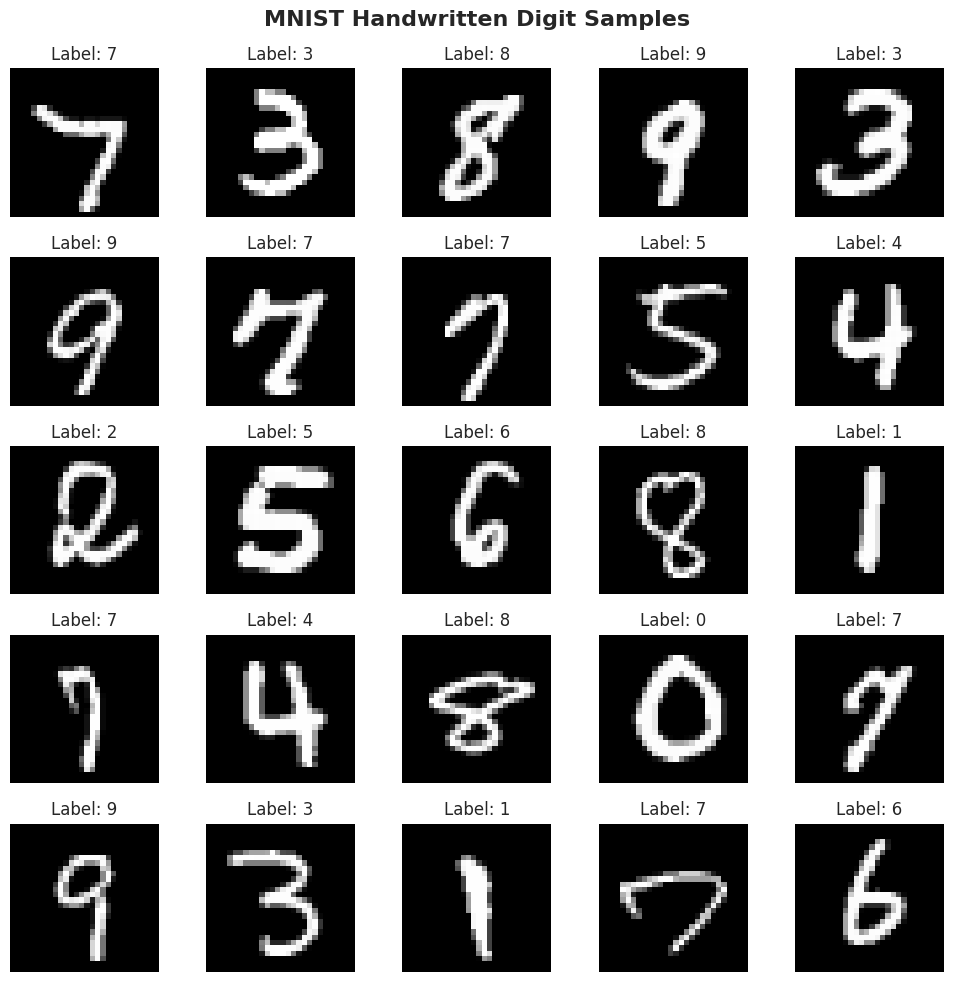

In [ ]:
plt.figure(figsize=(10, 10))

random_indices = np.random.choice(
    len(x_train),
    size=25,
    replace=False
)

for i, index in enumerate(random_indices):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_train[index], cmap="gray", vmin=0, vmax=255)
    plt.title(f"Label: {y_train[index]}")
    plt.axis("off")

plt.suptitle(
    "MNIST Handwritten Digit Samples",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

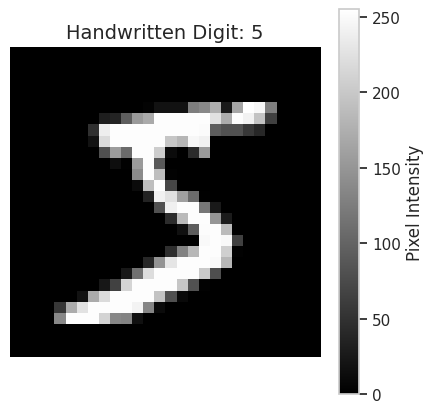

IMAGE INFORMATION
------------------------------
Actual digit label: 5
Image shape: (28, 28)
Total pixels: 784
Minimum pixel intensity: 0
Maximum pixel intensity: 255
------------------------------


In [ ]:
sample_index = 0

sample_image = x_train[sample_index]
sample_label = y_train[sample_index]

plt.figure(figsize=(5, 5))
plt.imshow(sample_image, cmap="gray", vmin=0, vmax=255)
plt.title(
    f"Handwritten Digit: {sample_label}",
    fontsize=14
)
plt.colorbar(label="Pixel Intensity")
plt.axis("off")
plt.show()

print("IMAGE INFORMATION")
print("------------------------------")
print("Actual digit label:", sample_label)
print("Image shape:", sample_image.shape)
print("Total pixels:", sample_image.size)
print("Minimum pixel intensity:", sample_image.min())
print("Maximum pixel intensity:", sample_image.max())
print("------------------------------")

In [ ]:
print("BEFORE NORMALIZATION")
print("------------------------------")
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Data type:", x_train.dtype)

x_train_normalized = x_train.astype("float32") / 255.0
x_test_normalized = x_test.astype("float32") / 255.0

print("\nAFTER NORMALIZATION")
print("------------------------------")
print("Minimum pixel value:", x_train_normalized.min())
print("Maximum pixel value:", x_train_normalized.max())
print("Data type:", x_train_normalized.dtype)
print("------------------------------")
print("Image normalization completed successfully!")

BEFORE NORMALIZATION
------------------------------
Minimum pixel value: 0
Maximum pixel value: 255
Data type: uint8

AFTER NORMALIZATION
------------------------------
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data type: float32
------------------------------
Image normalization completed successfully!


In [ ]:
print("TRAINING DATA VERIFICATION")
print("------------------------------")
print("Shape:", x_train_normalized.shape)
print("Data type:", x_train_normalized.dtype)
print("Minimum value:", x_train_normalized.min())
print("Maximum value:", x_train_normalized.max())

print("\nTESTING DATA VERIFICATION")
print("------------------------------")
print("Shape:", x_test_normalized.shape)
print("Data type:", x_test_normalized.dtype)
print("Minimum value:", x_test_normalized.min())
print("Maximum value:", x_test_normalized.max())

assert x_train_normalized.shape == (60000, 28, 28)
assert x_test_normalized.shape == (10000, 28, 28)
assert x_train_normalized.dtype == np.float32
assert x_test_normalized.dtype == np.float32
assert x_train_normalized.min() >= 0
assert x_train_normalized.max() <= 1
assert x_test_normalized.min() >= 0
assert x_test_normalized.max() <= 1

print("\nAll preprocessing checks passed successfully!")

TRAINING DATA VERIFICATION
------------------------------
Shape: (60000, 28, 28)
Data type: float32
Minimum value: 0.0
Maximum value: 1.0

TESTING DATA VERIFICATION
------------------------------
Shape: (10000, 28, 28)
Data type: float32
Minimum value: 0.0
Maximum value: 1.0

All preprocessing checks passed successfully!


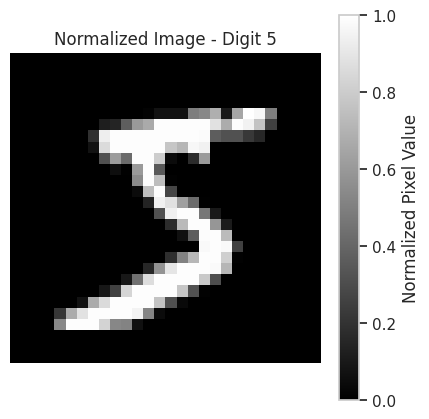

Original image shape: (28, 28)
Normalized image shape: (28, 28)
Original data type: uint8
Normalized data type: float32


In [ ]:
sample_index = 0

plt.figure(figsize=(5, 5))
plt.imshow(
    x_train_normalized[sample_index],
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.title(
    f"Normalized Image - Digit {y_train[sample_index]}"
)
plt.colorbar(label="Normalized Pixel Value")
plt.axis("off")
plt.show()

print("Original image shape:", x_train[sample_index].shape)
print("Normalized image shape:", x_train_normalized[sample_index].shape)
print("Original data type:", x_train.dtype)
print("Normalized data type:", x_train_normalized.dtype)

In [ ]:
model = keras.Sequential(
    [
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(
            32,
            kernel_size=(3, 3),
            padding="same",
            activation="relu"
        ),
        layers.BatchNormalization(),
        layers.Conv2D(
            32,
            kernel_size=(3, 3),
            padding="same",
            activation="relu"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        layers.Conv2D(
            64,
            kernel_size=(3, 3),
            padding="same",
            activation="relu"
        ),
        layers.BatchNormalization(),
        layers.Conv2D(
            64,
            kernel_size=(3, 3),
            padding="same",
            activation="relu"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        layers.Flatten(),
        layers.Dense(
            128,
            activation="relu"
        ),
        layers.BatchNormalization(),
        layers.Dropout(0.40),
        layers.Dense(
            10,
            activation="softmax"
        )
    ],
    name="MNIST_Improved_CNN"
)

print("Improved CNN architecture created successfully!")
print("Input image shape: 28 x 28 x 1")
print("Output classes: 10")

Improved CNN architecture created successfully!
Input image shape: 28 x 28 x 1
Output classes: 10


In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN MODEL COMPILED SUCCESSFULLY!")
print("-----------------------------------")
print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Loss Function: Sparse Categorical Crossentropy")
print("Evaluation Metric: Accuracy")
print("-----------------------------------")

CNN MODEL COMPILED SUCCESSFULLY!
-----------------------------------
Optimizer: Adam
Learning Rate: 0.001
Loss Function: Sparse Categorical Crossentropy
Evaluation Metric: Accuracy
-----------------------------------


In [ ]:
print("IMPROVED CNN MODEL ARCHITECTURE")
print("=" * 50)

model.summary()

print("\nMODEL VERIFICATION")
print("=" * 50)

print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

assert model.input_shape == (None, 28, 28, 1)
assert model.output_shape == (None, 10)

print("Total parameters:", model.count_params())

assert model.output_shape[-1] == 10

print("\nAll CNN architecture checks passed!")
print("Model is ready for training preparation.")

IMPROVED CNN MODEL ARCHITECTURE


Model: "MNIST_Improved_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 469,098 (1.79 MB)

 Trainable params: 468,458 (1.79 MB)

 Non-trainable params: 640 (2.50 KB)


MODEL VERIFICATION
Input shape: (None, 28, 28, 1)
Output shape: (None, 10)
Total parameters: 469098

All CNN architecture checks passed!
Model is ready for training preparation.


In [ ]:
from sklearn.model_selection import train_test_split

x_train_model, x_val, y_train_model, y_val = train_test_split(
    x_train_normalized,
    y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

x_train_cnn = np.expand_dims(
    x_train_model,
    axis=-1
)

x_val_cnn = np.expand_dims(
    x_val,
    axis=-1
)

x_test_cnn = np.expand_dims(
    x_test_normalized,
    axis=-1
)

print("CNN DATA PREPARATION")
print("=" * 45)

print("\nTRAINING DATA")
print("Images:", x_train_cnn.shape)
print("Labels:", y_train_model.shape)

print("\nVALIDATION DATA")
print("Images:", x_val_cnn.shape)
print("Labels:", y_val.shape)

print("\nTESTING DATA")
print("Images:", x_test_cnn.shape)
print("Labels:", y_test.shape)

print("\nDATA TYPE")
print("Training:", x_train_cnn.dtype)
print("Validation:", x_val_cnn.dtype)
print("Testing:", x_test_cnn.dtype)

assert x_train_cnn.shape == (54000, 28, 28, 1)
assert x_val_cnn.shape == (6000, 28, 28, 1)
assert x_test_cnn.shape == (10000, 28, 28, 1)

assert y_train_model.shape == (54000,)
assert y_val.shape == (6000,)
assert y_test.shape == (10000,)

assert x_train_cnn.min() >= 0
assert x_train_cnn.max() <= 1

assert x_val_cnn.min() >= 0
assert x_val_cnn.max() <= 1

assert x_test_cnn.min() >= 0
assert x_test_cnn.max() <= 1

print("\n" + "=" * 45)
print("ALL CNN DATA PREPARATION CHECKS PASSED!")

CNN DATA PREPARATION

TRAINING DATA
Images: (54000, 28, 28, 1)
Labels: (54000,)

VALIDATION DATA
Images: (6000, 28, 28, 1)
Labels: (6000,)

TESTING DATA
Images: (10000, 28, 28, 1)
Labels: (10000,)

DATA TYPE
Training: float32
Validation: float32
Testing: float32

ALL CNN DATA PREPARATION CHECKS PASSED!


In [ ]:
EPOCHS = 8
BATCH_SIZE = 256

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=0.00001,
    verbose=1
)

callbacks = [
    early_stopping,
    reduce_lr
]

print("STARTING LIGHTWEIGHT CNN TRAINING")
print("=" * 45)

print("Maximum Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Early Stopping: Enabled")
print("Learning Rate Reduction: Enabled")

history = model.fit(
    x_train_cnn,
    y_train_model,
    validation_data=(x_val_cnn, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

print("=" * 45)
print("CNN TRAINING COMPLETED!")

print(
    "Epochs completed:",
    len(history.history["loss"])
)

print(
    "Best validation accuracy:",
    round(max(history.history["val_accuracy"]) * 100, 2),
    "%"
)

print("=" * 45)

STARTING LIGHTWEIGHT CNN TRAINING
Maximum Epochs: 8
Batch Size: 256
Early Stopping: Enabled
Learning Rate Reduction: Enabled
Epoch 1/8
211/211 ━━━━━━━━━━━━━━━━━━━━ 291s 1s/step - accuracy: 0.9387 - loss: 0.2018 - val_accuracy: 0.1123 - val_loss: 5.5674 - learning_rate: 0.0010
Epoch 2/8
211/211 ━━━━━━━━━━━━━━━━━━━━ 285s 1s/step - accuracy: 0.9814 - loss: 0.0638 - val_accuracy: 0.5538 - val_loss: 1.6048 - learning_rate: 0.0010
Epoch 3/8
211/211 ━━━━━━━━━━━━━━━━━━━━ 281s 1s/step - accuracy: 0.9858 - loss: 0.0467 - val_accuracy: 0.9845 - val_loss: 0.0557 - learning_rate: 0.0010
Epoch 4/8
211/211 ━━━━━━━━━━━━━━━━━━━━ 280s 1s/step - accuracy: 0.9884 - loss: 0.0374 - val_accuracy: 0.9888 - val_loss: 0.0402 - learning_rate: 0.0010
Epoch 5/8
211/211 ━━━━━━━━━━━━━━━━━━━━ 285s 1s/step - accuracy: 0.9899 - loss: 0.0323 - val_accuracy: 0.9910 - val_loss: 0.0307 - learning_rate: 0.0010
Epoch 6/8
211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9914 - loss: 0.0277
Epoch 6: ReduceLROnPlateau redu

In [ ]:
training_accuracy = history.history["accuracy"]
validation_accuracy = history.history["val_accuracy"]

training_loss = history.history["loss"]
validation_loss = history.history["val_loss"]

training_history = pd.DataFrame({
    "Epoch": range(1, len(training_accuracy) + 1),
    "Training Accuracy": training_accuracy,
    "Validation Accuracy": validation_accuracy,
    "Training Loss": training_loss,
    "Validation Loss": validation_loss
})

print("CNN TRAINING HISTORY")
print("=" * 55)

display(training_history.round(4))

print("=" * 55)

print(
    "Completed Epochs:",
    len(training_accuracy)
)

print(
    "Best Training Accuracy:",
    round(max(training_accuracy) * 100, 2),
    "%"
)

print(
    "Best Validation Accuracy:",
    round(max(validation_accuracy) * 100, 2),
    "%"
)

print(
    "Best Validation Loss:",
    round(min(validation_loss), 4)
)

print("=" * 55)
print("CNN TRAINING HISTORY GENERATED SUCCESSFULLY!")

CNN TRAINING HISTORY


,Epoch,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss
0,1,0.9387,0.1123,0.2018,5.5674
1,2,0.9814,0.5538,0.0638,1.6048
2,3,0.9858,0.9845,0.0467,0.0557
3,4,0.9884,0.9888,0.0374,0.0402
4,5,0.9899,0.9910,0.0323,0.0307
5,6,0.9917,0.9892,0.0276,0.0332
6,7,0.9939,0.9900,0.0198,0.0327
7,8,0.9951,0.9917,0.0159,0.0286


Completed Epochs: 8
Best Training Accuracy: 99.51 %
Best Validation Accuracy: 99.17 %
Best Validation Loss: 0.0286
CNN TRAINING HISTORY GENERATED SUCCESSFULLY!


In [ ]:
test_loss, test_accuracy = model.evaluate(
    x_test_cnn,
    y_test,
    batch_size=256,
    verbose=1
)

print("\n" + "=" * 50)
print("CNN MODEL TEST EVALUATION")
print("=" * 50)

print(f"Test Accuracy : {test_accuracy * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")

print("=" * 50)
print("TEST EVALUATION COMPLETED SUCCESSFULLY!")

40/40 ━━━━━━━━━━━━━━━━━━━━ 11s 278ms/step - accuracy: 0.9940 - loss: 0.0175

CNN MODEL TEST EVALUATION
Test Accuracy : 99.40%
Test Loss     : 0.0175
TEST EVALUATION COMPLETED SUCCESSFULLY!


40/40 ━━━━━━━━━━━━━━━━━━━━ 10s 236ms/step

CNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9949    0.9980    0.9964       980
           1     0.9930    0.9991    0.9960      1135
           2     0.9971    0.9952    0.9961      1032
           3     0.9912    0.9990    0.9951      1010
           4     0.9959    0.9939    0.9949       982
           5     0.9933    0.9922    0.9927       892
           6     0.9989    0.9843    0.9916       958
           7     0.9894    0.9961    0.9927      1028
           8     0.9938    0.9908    0.9923       974
           9     0.9930    0.9901    0.9916      1009

    accuracy                         0.9940     10000
   macro avg     0.9941    0.9939    0.9939     10000
weighted avg     0.9940    0.9940    0.9940     10000



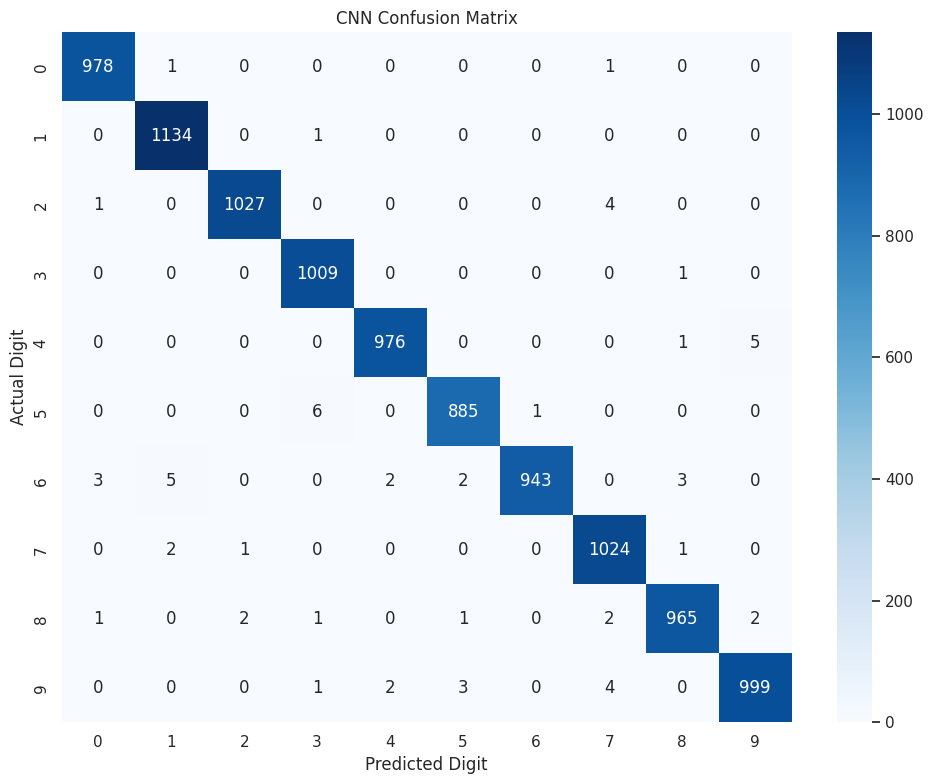

DETAILED PREDICTION ANALYSIS COMPLETED!


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_prob = model.predict(
    x_test_cnn,
    batch_size=256,
    verbose=1
)

y_pred = np.argmax(y_pred_prob, axis=1)

print("\n" + "=" * 60)
print("CNN CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[str(i) for i in range(10)],
        digits=4
    )
)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.tight_layout()
plt.show()

print("DETAILED PREDICTION ANALYSIS COMPLETED!")

In [ ]:
y_actual = y_test

report = classification_report(
    y_actual,
    y_pred,
    labels=np.arange(10),
    target_names=[str(i) for i in range(10)],
    digits=4,
    zero_division=0
)

print("CLASSIFICATION REPORT")
print("-----------------------------------")
print("Digit-wise Performance")
print("-----------------------------------")
print(report)

CLASSIFICATION REPORT
-----------------------------------
Digit-wise Performance
-----------------------------------
              precision    recall  f1-score   support

           0     0.9949    0.9980    0.9964       980
           1     0.9930    0.9991    0.9960      1135
           2     0.9971    0.9952    0.9961      1032
           3     0.9912    0.9990    0.9951      1010
           4     0.9959    0.9939    0.9949       982
           5     0.9933    0.9922    0.9927       892
           6     0.9989    0.9843    0.9916       958
           7     0.9894    0.9961    0.9927      1028
           8     0.9938    0.9908    0.9923       974
           9     0.9930    0.9901    0.9916      1009

    accuracy                         0.9940     10000
   macro avg     0.9941    0.9939    0.9939     10000
weighted avg     0.9940    0.9940    0.9940     10000



In [ ]:
cm = confusion_matrix(
    y_actual,
    y_pred,
    labels=np.arange(10)
)

print("CONFUSION MATRIX")
print("-----------------------------------")
print(cm)
print("-----------------------------------")
print("Confusion matrix shape:", cm.shape)
print("Total testing predictions:", cm.sum())

assert cm.shape == (10, 10)
assert cm.sum() == len(y_test)

print("Confusion matrix verification successful!")

CONFUSION MATRIX
-----------------------------------
[[ 978    1    0    0    0    0    0    1    0    0]
 [   0 1134    0    1    0    0    0    0    0    0]
 [   1    0 1027    0    0    0    0    4    0    0]
 [   0    0    0 1009    0    0    0    0    1    0]
 [   0    0    0    0  976    0    0    0    1    5]
 [   0    0    0    6    0  885    1    0    0    0]
 [   3    5    0    0    2    2  943    0    3    0]
 [   0    2    1    0    0    0    0 1024    1    0]
 [   1    0    2    1    0    1    0    2  965    2]
 [   0    0    0    1    2    3    0    4    0  999]]
-----------------------------------
Confusion matrix shape: (10, 10)
Total testing predictions: 10000
Confusion matrix verification successful!


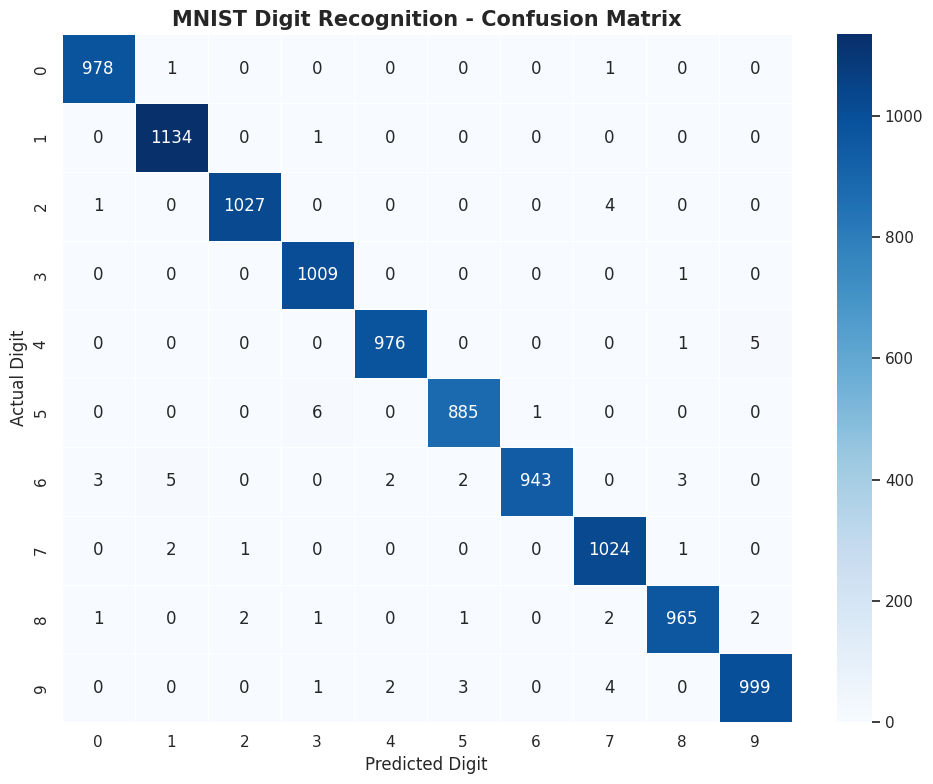

In [ ]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    xticklabels=np.arange(10),
    yticklabels=np.arange(10)
)

plt.title(
    "MNIST Digit Recognition - Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")

plt.tight_layout()
plt.show()

In [ ]:
overall_accuracy = accuracy_score(y_actual, y_pred)

report_dict = classification_report(
    y_actual,
    y_pred,
    labels=np.arange(10),
    output_dict=True,
    zero_division=0
)

macro_precision = report_dict["macro avg"]["precision"]
macro_recall = report_dict["macro avg"]["recall"]
macro_f1 = report_dict["macro avg"]["f1-score"]
weighted_f1 = report_dict["weighted avg"]["f1-score"]

evaluation_summary = pd.DataFrame({
    "Performance Metric": [
        "Testing Accuracy",
        "Testing Loss",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score",
        "Weighted F1-Score"
    ],
    "Result": [
        overall_accuracy * 100,
        test_loss,
        macro_precision,
        macro_recall,
        macro_f1,
        weighted_f1
    ],
    "Unit": [
        "%",
        "Loss",
        "Score",
        "Score",
        "Score",
        "Score"
    ]
})

print("FINAL MODEL EVALUATION SUMMARY")
print("-----------------------------------")

display(evaluation_summary.round(4))

print("-----------------------------------")
print("Total testing images:", len(y_test))
print("Correct predictions:", int(np.sum(y_actual == y_pred)))
print("Incorrect predictions:", int(np.sum(y_actual != y_pred)))
print("-----------------------------------")
print("Final evaluation completed successfully!")

FINAL MODEL EVALUATION SUMMARY
-----------------------------------


,Performance Metric,Result,Unit
0,Testing Accuracy,99.4000,%
1,Testing Loss,0.0175,Loss
2,Macro Precision,0.9941,Score
3,Macro Recall,0.9939,Score
4,Macro F1-Score,0.9939,Score
5,Weighted F1-Score,0.9940,Score


-----------------------------------
Total testing images: 10000
Correct predictions: 9940
Incorrect predictions: 60
-----------------------------------
Final evaluation completed successfully!


40/40 ━━━━━━━━━━━━━━━━━━━━ 15s 357ms/step


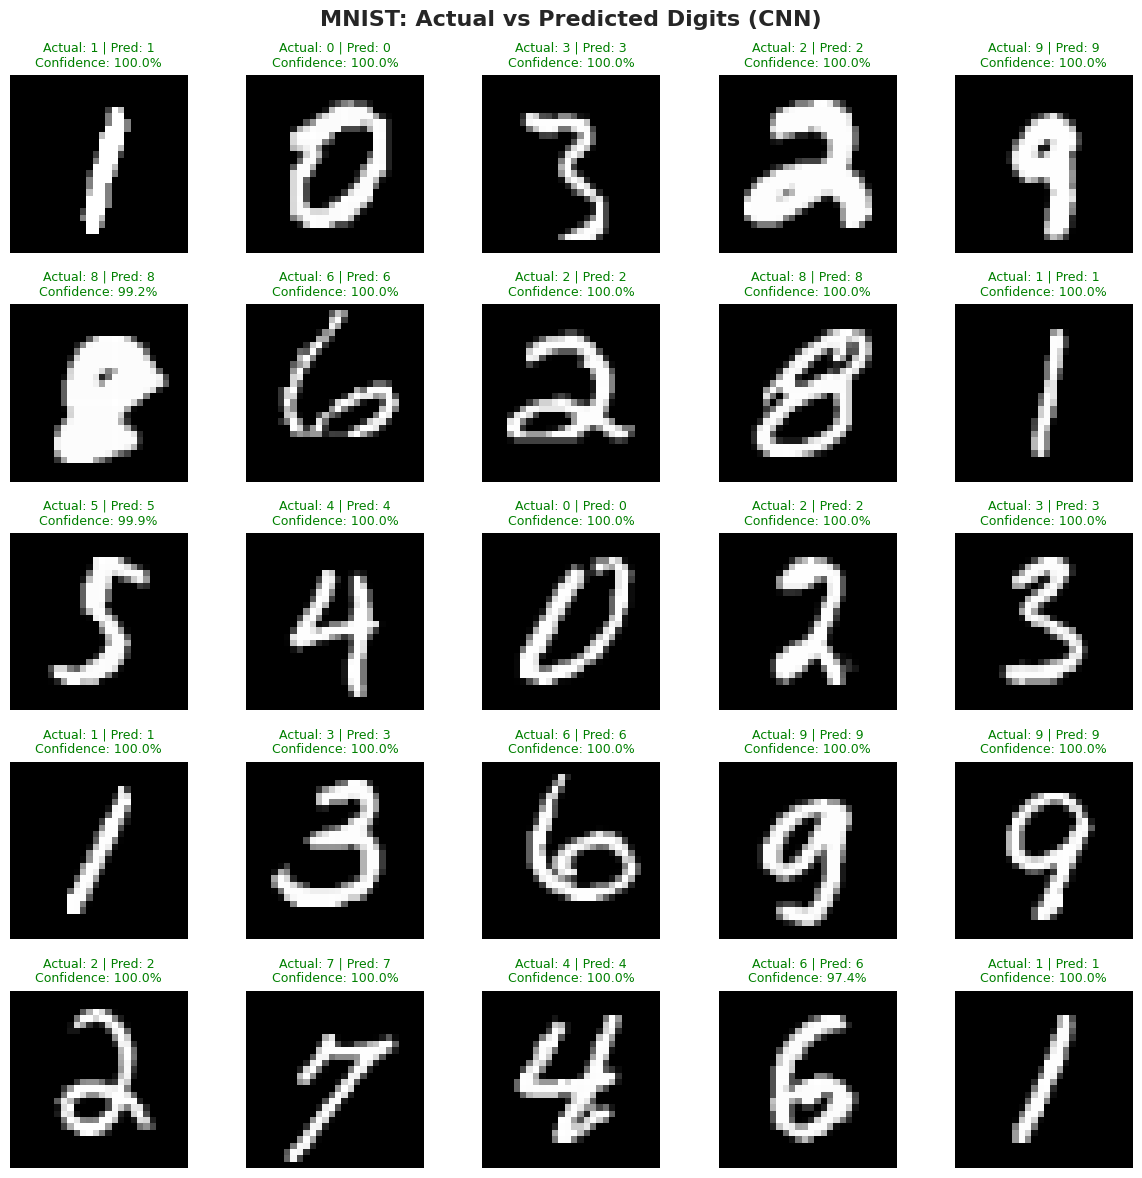


25 CNN digit predictions visualized successfully!


In [ ]:
y_actual = np.asarray(y_test)

y_probabilities = model.predict(
    x_test_cnn,
    batch_size=256,
    verbose=1
)

y_pred = np.argmax(y_probabilities, axis=1)

assert len(x_test) == len(y_actual)
assert len(y_pred) == len(y_actual)
assert y_probabilities.shape == (len(y_actual), 10)

rng = np.random.default_rng(42)

selected_indices = rng.choice(
    len(x_test),
    size=25,
    replace=False
)

plt.figure(figsize=(12, 12))

for i, index in enumerate(selected_indices):
    plt.subplot(5, 5, i + 1)
    plt.imshow(
        x_test[index],
        cmap="gray",
        vmin=0,
        vmax=255
    )

    actual_digit = int(y_actual[index])
    predicted_digit = int(y_pred[index])

    confidence = (
        y_probabilities[index, predicted_digit] * 100
    )

    correct = actual_digit == predicted_digit
    title_color = "green" if correct else "red"

    plt.title(
        f"Actual: {actual_digit} | Pred: {predicted_digit}\n"
        f"Confidence: {confidence:.1f}%",
        fontsize=9,
        color=title_color
    )
    plt.axis("off")

plt.suptitle(
    "MNIST: Actual vs Predicted Digits (CNN)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("\n25 CNN digit predictions visualized successfully!")

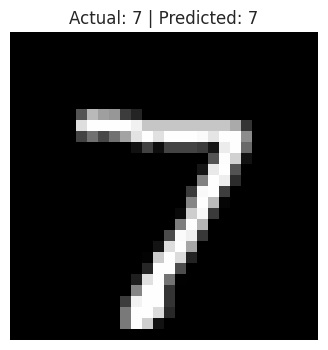

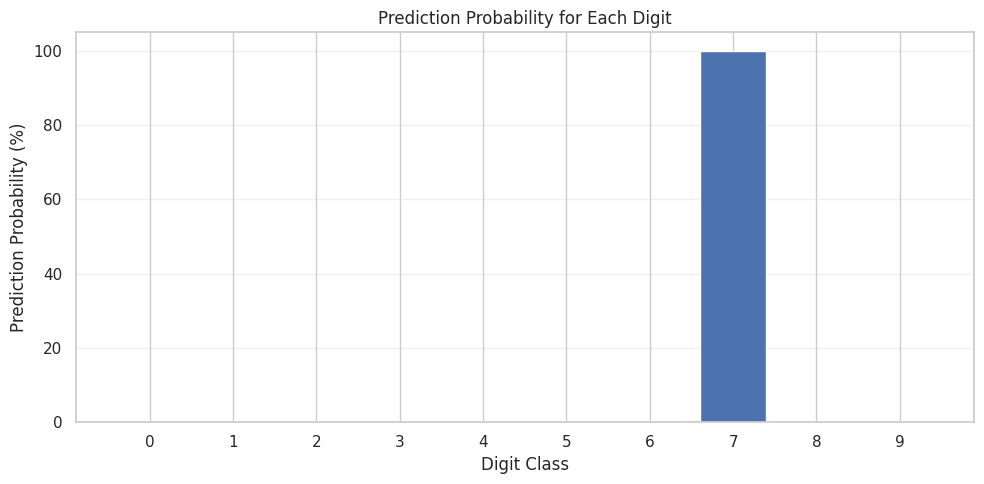

INDIVIDUAL PREDICTION DETAILS
-----------------------------------
Actual digit: 7
Predicted digit: 7
Prediction confidence: 100.0 %
Prediction correct: True
-----------------------------------


In [ ]:
sample_index = 0

actual_digit = y_actual[sample_index]
predicted_digit = y_pred[sample_index]

probabilities = y_probabilities[sample_index]
confidence = probabilities[predicted_digit] * 100

plt.figure(figsize=(4, 4))
plt.imshow(
    x_test[sample_index],
    cmap="gray",
    vmin=0,
    vmax=255
)
plt.title(
    f"Actual: {actual_digit} | Predicted: {predicted_digit}"
)
plt.axis("off")
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(
    np.arange(10),
    probabilities * 100
)
plt.xticks(np.arange(10))
plt.xlabel("Digit Class")
plt.ylabel("Prediction Probability (%)")
plt.title("Prediction Probability for Each Digit")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("INDIVIDUAL PREDICTION DETAILS")
print("-----------------------------------")
print("Actual digit:", actual_digit)
print("Predicted digit:", predicted_digit)
print("Prediction confidence:", round(confidence, 2), "%")
print(
    "Prediction correct:",
    actual_digit == predicted_digit
)
print("-----------------------------------")

MISCLASSIFICATION ANALYSIS
-----------------------------------
Total incorrect predictions: 60
-----------------------------------


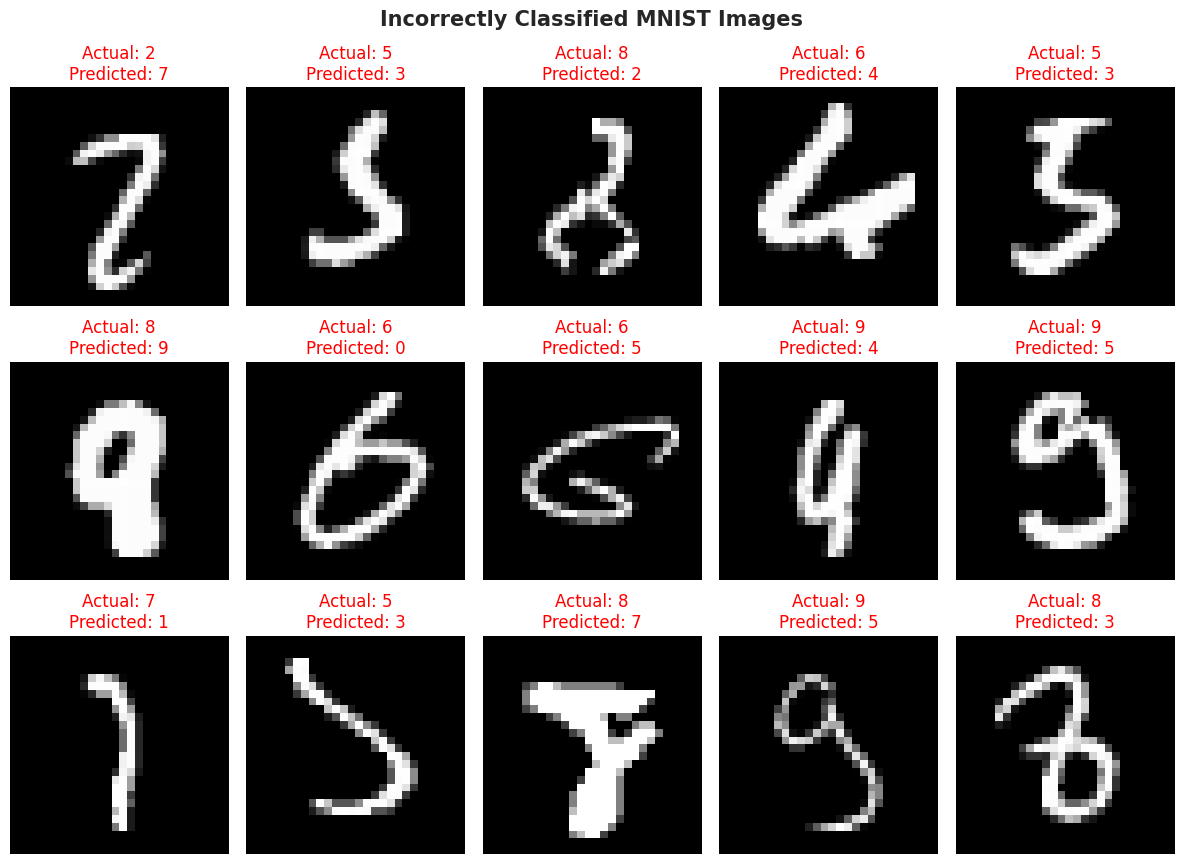

-----------------------------------
Misclassification analysis completed successfully!


In [ ]:
misclassified_indices = np.where(
    y_actual != y_pred
)[0]

print("MISCLASSIFICATION ANALYSIS")
print("-----------------------------------")
print(
    "Total incorrect predictions:",
    len(misclassified_indices)
)
print("-----------------------------------")

if len(misclassified_indices) > 0:
    selected_errors = misclassified_indices[:15]
    number_of_images = len(selected_errors)
    columns = 5
    rows = int(np.ceil(number_of_images / columns))

    plt.figure(figsize=(12, 3 * rows))

    for i, index in enumerate(selected_errors):
        plt.subplot(rows, columns, i + 1)
        plt.imshow(
            x_test[index],
            cmap="gray",
            vmin=0,
            vmax=255
        )
        plt.title(
            f"Actual: {y_actual[index]}\n"
            f"Predicted: {y_pred[index]}",
            color="red"
        )
        plt.axis("off")

    plt.suptitle(
        "Incorrectly Classified MNIST Images",
        fontsize=15,
        fontweight="bold"
    )
    plt.tight_layout()
    plt.show()
else:
    print("No incorrect predictions were found!")

print("-----------------------------------")
print(
    "Misclassification analysis completed successfully!"
)

In [ ]:
%pip -q install "gradio>=5.0,<7.0"

import gradio as gr
from PIL import Image

print("GRADIO INSTALLATION DETAILS")
print("-----------------------------------")
print("Gradio Version:", gr.__version__)
print("ImageEditor Available:", hasattr(gr, "ImageEditor"))
print("-----------------------------------")
print("Gradio environment ready!")

GRADIO INSTALLATION DETAILS
-----------------------------------
Gradio Version: 6.31.0
ImageEditor Available: True
-----------------------------------
Gradio environment ready!


In [ ]:
from PIL import Image

def preprocess_canvas(editor_value):
    if isinstance(editor_value, dict):
        image = editor_value.get("composite")
        if image is None:
            image = editor_value.get("background")
    else:
        image = editor_value

    if image is None:
        raise gr.Error("Please upload or draw a digit!")

    image_array = np.asarray(image)
    if image_array.size == 0:
        raise gr.Error("Empty image! Please upload a valid digit.")

    image_float = image_array.astype(np.float32)
    if not np.isfinite(image_float).all():
        raise gr.Error("Invalid image pixel values!")

    if image_float.max() <= 1.0:
        image_float *= 255.0

    image_float = np.clip(image_float, 0, 255)

    if image_float.ndim == 3:
        channels = image_float.shape[-1]
        if channels == 1:
            gray = image_float[..., 0]
        elif channels in (3, 4):
            gray = (
                0.299 * image_float[..., 0]
                + 0.587 * image_float[..., 1]
                + 0.114 * image_float[..., 2]
            )
            if channels == 4:
                alpha = image_float[..., 3] / 255.0
                gray = gray * alpha
        else:
            raise gr.Error("Unsupported image channel format!")
    elif image_float.ndim == 2:
        gray = image_float
    else:
        raise gr.Error("Invalid image format!")

    gray_image = np.clip(
        gray, 0, 255
    ).astype(np.uint8)

    border_pixels = np.concatenate([
        gray_image[0, :],
        gray_image[-1, :],
        gray_image[:, 0],
        gray_image[:, -1]
    ])

    if np.median(border_pixels) > 127:
        gray_image = 255 - gray_image

    if gray_image.max() <= 20:
        raise gr.Error("Blank image! Please draw a digit.")

    if gray_image.shape == (28, 28):
        return gray_image.astype(np.float32) / 255.0

    mask = gray_image > 20
    coordinates = np.argwhere(mask)
    if coordinates.size == 0:
        raise gr.Error("No digit detected!")

    top, left = coordinates.min(axis=0)
    bottom, right = coordinates.max(axis=0)

    cropped_digit = gray_image[
        top:bottom + 1,
        left:right + 1
    ]

    height, width = cropped_digit.shape
    scale = 20.0 / max(height, width)
    new_height = max(1, int(round(height * scale)))
    new_width = max(1, int(round(width * scale)))

    resized_digit = Image.fromarray(
        cropped_digit
    ).resize(
        (new_width, new_height),
        Image.Resampling.LANCZOS
    )

    final_canvas = Image.new(
        "L",
        (28, 28),
        color=0
    )

    position = (
        (28 - new_width) // 2,
        (28 - new_height) // 2
    )

    final_canvas.paste(resized_digit, position)
    processed_image = (
        np.asarray(final_canvas, dtype=np.float32) / 255.0
    )
    return processed_image

print("CNN-compatible preprocessing function created successfully!")

CNN-compatible preprocessing function created successfully!


In [ ]:
assert model.input_shape == (None, 28, 28, 1)
assert model.output_shape == (None, 10)


def predict_digit(editor_value):
    processed_image = preprocess_canvas(editor_value)
    assert processed_image.shape == (28, 28)

    input_image = processed_image.reshape(1, 28, 28, 1)
    probabilities = model.predict(
        input_image,
        verbose=0
    )[0]

    if probabilities.shape != (10,):
        raise gr.Error("Unexpected model prediction output!")

    predicted_digit = int(np.argmax(probabilities))
    confidence = float(probabilities[predicted_digit]) * 100

    class_scores = {
        str(i): float(probabilities[i])
        for i in range(10)
    }

    result = (
        f"Predicted Digit: {predicted_digit}\n"
        f"Confidence: {confidence:.2f}%\n"
        f"Model: MNIST Convolutional Neural Network (CNN)"
    )

    preview_image = (
        processed_image * 255
    ).astype(np.uint8)

    return (
        class_scores,
        result,
        preview_image
    )


print("CNN digit prediction function created successfully!")

CNN digit prediction function created successfully!


In [ ]:
blank_canvas = np.zeros(
    (280, 280),
    dtype=np.uint8
)

with gr.Blocks(
    title="MNIST CNN Handwritten Digit Recognition"
) as demo:

    gr.Markdown(
        """
        # Handwritten Digit Recognition

        ### CNN-Based MNIST Classification

        Draw a digit from 0 to 9 or upload a handwritten
        digit image. Select white or black brush colour
        according to your canvas background.

        Click Predict Digit to see the result.
        """
    )

    with gr.Row():
        with gr.Column():
            drawing_canvas = gr.ImageEditor(
                value=blank_canvas,
                sources=["upload"],
                type="numpy",
                image_mode="L",
                brush=gr.Brush(
                    default_size=12,
                    colors=["#FFFFFF", "#000000"],
                    default_color="#FFFFFF",
                    color_mode="fixed"
                ),
                canvas_size=(280, 280),
                fixed_canvas=True,
                layers=False,
                transforms=(),
                height=340,
                width=340,
                label="Draw or Upload Your Digit"
            )
            predict_button = gr.Button(
                "Predict Digit",
                variant="primary"
            )

        with gr.Column():
            prediction_output = gr.Label(
                label="Top 3 Predicted Digits",
                num_top_classes=3
            )
            result_output = gr.Textbox(
                label="CNN Prediction Result",
                interactive=False,
                lines=4
            )
            processed_output = gr.Image(
                label="Processed 28 x 28 Image",
                type="numpy"
            )

    predict_button.click(
        fn=predict_digit,
        inputs=drawing_canvas,
        outputs=[
            prediction_output,
            result_output,
            processed_output
        ]
    )

    gr.Markdown(
        """
        ---

        **Project:** Handwritten Digit Recognition Using CNN

        **Dataset:** MNIST

        **Model:** Convolutional Neural Network

        **Classes:** 0–9

        **Disclaimer:** Predictions depend on handwriting
        quality and similarity to the MNIST dataset.
        """
    )

demo.launch(
    share=True,
    debug=True,
    theme=gr.themes.Soft()
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://5a6a87655b0ed9981b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://5a6a87655b0ed9981b.gradio.live


In [ ]:
import os

model_path = "/content/mnist_cnn_model.keras"
model.save(model_path)

print("CNN MODEL SAVED SUCCESSFULLY!")
print("File name:", model_path)
print("File size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")

assert os.path.exists(model_path)
print("MODEL FILE VERIFICATION: SUCCESSFUL!")

CNN MODEL SAVED SUCCESSFULLY!
File name: /content/mnist_cnn_model.keras
File size: 5.44 MB
MODEL FILE VERIFICATION: SUCCESSFUL!


In [ ]:
import os
from tensorflow import keras

model_path = "/content/mnist_cnn_model.keras"

assert os.path.exists(model_path), "Saved model file not found!"

loaded_model = keras.models.load_model(model_path)

assert loaded_model.input_shape == (None, 28, 28, 1)
assert loaded_model.output_shape == (None, 10)

loaded_loss, loaded_accuracy = loaded_model.evaluate(
    x_test_cnn,
    y_test,
    batch_size=256,
    verbose=1
)

print("\n" + "=" * 50)
print("SAVED CNN MODEL VERIFICATION")
print("=" * 50)

print(f"Loaded Model Accuracy: {loaded_accuracy * 100:.2f}%")
print(f"Loaded Model Loss: {loaded_loss:.4f}")
print(f"Model File Size: {os.path.getsize(model_path) / (1024 * 1024):.2f} MB")
print("=" * 50)
print("MODEL SAVED AND LOADED SUCCESSFULLY!")

40/40 ━━━━━━━━━━━━━━━━━━━━ 11s 250ms/step - accuracy: 0.9940 - loss: 0.0175

SAVED CNN MODEL VERIFICATION
Loaded Model Accuracy: 99.40%
Loaded Model Loss: 0.0175
Model File Size: 5.44 MB
MODEL SAVED AND LOADED SUCCESSFULLY!


In [ ]:
from google.colab import files
files.download("/content/mnist_cnn_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>